# ۰۹ · شروع سادهٔ TensorFlow و PyTorch؛ از داده تا مدل

یک کار یکسان را با هر دو کتابخانه انجام می‌دهیم: چند تصویر MNIST می‌خوانیم، مقدار پیکسل‌ها را تبدیل می‌کنیم،
مدل کوچک می‌سازیم، آموزش می‌دهیم، پیش‌بینی می‌کنیم و مدل را ذخیره می‌کنیم.
زمان پیشنهادی تدریس: ۹۰ تا ۱۲۰ دقیقه. درس ۰۸ پیش‌نیاز مناسبی است.

**روش مطالعه:** سلول‌ها را از بالا به پایین اجرا کنید. هر بخش یک مفهوم کوچک و یک مثال دارد.
پیش‌نیاز فقط آشنایی مقدماتی با پایتون و لیست است. خروجی‌های فایل از اجرای واقعی کدها ذخیره شده‌اند.
این درس برای اجرا روی CPU نوشته شده است.

<style>
.jp-MarkdownOutput,.text_cell_render {direction:rtl;text-align:right;font-family:Tahoma,Arial,sans-serif;line-height:1.9}
.jp-MarkdownOutput pre,.text_cell_render pre,.jp-CodeCell,.jp-OutputArea-output {direction:ltr;text-align:left}
mjx-container,.MathJax {direction:ltr} table {direction:ltr}
</style>

## ۱. تاریخچهٔ کوتاه و کاربرد

- **TensorFlow** در نوامبر ۲۰۱۵ توسط Google متن‌باز شد. در نسخهٔ ۲، منتشرشده در سپتامبر ۲۰۱۹، اجرای مستقیم یا eager و کار با Keras محور اصلی شروع کار شدند.
- **PyTorch** از خانوادهٔ Torch و کار تیم FAIR شکل گرفت و در اوایل ۲۰۱۷ عرضه شد. نسخهٔ پایدار ۱٫۰ آن در دسامبر ۲۰۱۸ منتشر شد.
- هر دو برای ساخت و آموزش شبکهٔ عصبی، محاسبات تنسوری و مشتق‌گیری خودکار استفاده می‌شوند.

در این درس، TensorFlow را با `tf.keras` به کار می‌بریم. Keras ابزارهایی مانند `Sequential`، `fit` و `predict` دارد.
در PyTorch از `torch.nn` برای لایه‌ها و از `torch.optim` برای تغییر وزن‌ها استفاده می‌کنیم.
هر دو می‌توانند محاسبات را مستقیم اجرا کنند؛ ساده‌سازی «یکی فقط گراف ثابت و دیگری فقط گراف پویا» توصیف مناسبی برای نسخه‌های فعلی نیست.

منابع تاریخچه: [معرفی TensorFlow](https://blog.google/innovation-and-ai/products/tensorflow-smarter-machine-learning-for/)،
[انتشار TensorFlow 2](https://blog.tensorflow.org/2019/09/tensorflow-20-is-now-available.html)،
[معرفی PyTorch 1.0 و سابقهٔ آن](https://engineering.fb.com/2018/12/07/ai-research/pytorch-developer-ecosystem-expands-1-0-stable-release/).

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import tensorflow as tf
import torch
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)

print('NumPy:', np.__version__)
print('TensorFlow:', tf.__version__)
print('PyTorch:', torch.__version__)

C:\Program Files\Python311\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


NumPy: 2.2.6
TensorFlow: 2.20.0
PyTorch: 2.9.1+cpu


In [2]:
from pathlib import Path
from tensorflow import keras
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent

## ۲. نقشهٔ کار

۱. خواندن داده و دیدن شکل آن.

۲. تبدیل پیکسل‌های ۰ تا ۲۵۵ به عددهای اعشاری ۰ تا ۱.

۳. ساخت batch برای آموزش.

۴. تعریف مدل و loss و optimizer.

۵. آموزش، ارزیابی، پیش‌بینی و ذخیرهٔ مدل.

**سه واژه:** مدل از ورودی خروجی می‌سازد؛ loss میزان خطا را می‌سنجد؛ optimizer وزن‌ها را برای کم‌کردن خطا تغییر می‌دهد.

## ۳. خواندن MNIST

هر تصویر ۲۸ سطر و ۲۸ ستون دارد و برچسب آن یک عدد ۰ تا ۹ است.
اگر دادهٔ همراه مجموعه موجود باشد، فایل محلی خوانده می‌شود؛ در غیر این صورت Keras آن را دریافت می‌کند.
پس از خواندن، دادهٔ NumPy را می‌توان به هر دو کتابخانه داد.

In [3]:
path = root / 'data' / 'mnist.npz'
if path.exists():
    with np.load(path) as data:
        raw_x, raw_y = data['x_train'], data['y_train']
        test_x, test_y = data['x_test'], data['y_test']
else:
    (raw_x, raw_y), (test_x, test_y) = keras.datasets.mnist.load_data()

print('Training images:', raw_x.shape, raw_x.dtype)
print('Training labels:', raw_y.shape, raw_y.dtype)
print('Test images:', test_x.shape)
print('Pixel range:', raw_x.min(), raw_x.max())

Training images: (60000, 28, 28) uint8
Training labels: (60000,) uint8
Test images: (10000, 28, 28)
Pixel range: 0 255


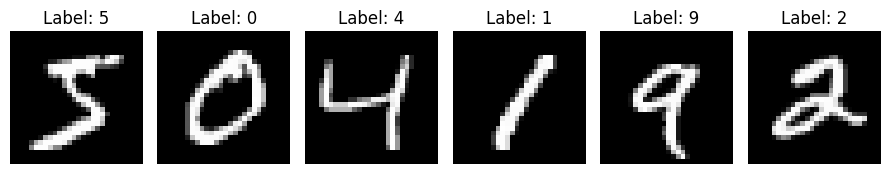

In [4]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for i, ax in enumerate(axes):
    ax.imshow(raw_x[i], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Label: {raw_y[i]}')
    ax.axis('off')
plt.tight_layout(); plt.show()

## ۴. تبدیل داده یا transform

یک transform ورودی را به شکل یا مقیاس مناسب تبدیل می‌کند.
تبدیل این درس ساده است: نوع را `float32` می‌کنیم و بر ۲۵۵ تقسیم می‌کنیم.
همین تبدیل باید روی train، validation، test و تصویر جدید انجام شود.

برای اجرای سبک، ۸۰۰۰ نمونهٔ train، ۱۰۰۰ validation و ۲۰۰۰ test می‌گیریم.
validation از قسمت جداگانه‌ای از دادهٔ آموزشی اصلی برداشته می‌شود و با train هم‌پوشانی ندارد.
دادهٔ test رسمی برای آموزش استفاده نمی‌شود.

In [5]:
x_train = raw_x[:8000].astype('float32') / 255.0
y_train = raw_y[:8000].astype('int64')
x_val = raw_x[50000:51000].astype('float32') / 255.0
y_val = raw_y[50000:51000].astype('int64')
x_test = test_x[:2000].astype('float32') / 255.0
y_test = test_y[:2000].astype('int64')

print('Train:', x_train.shape, 'validation:', x_val.shape, 'test:', x_test.shape)
print('Input dtype / range:', x_train.dtype, x_train.min(), x_train.max())
print('Label dtype:', y_train.dtype)

Train: (8000, 28, 28) validation: (1000, 28, 28) test: (2000, 28, 28)


Input dtype / range: float32 0.0 1.0
Label dtype: int64


### همان transform با دستور هر کتابخانه

ورودی خام این مثال `uint8` است. در TensorFlow از `tf.cast` و در PyTorch از `.float()` استفاده می‌کنیم.
از اینجا به بعد، دادهٔ نرمال‌شدهٔ NumPy را که در سلول قبل ساختیم مصرف می‌کنیم؛ دوباره آن را بر ۲۵۵ تقسیم نمی‌کنیم.

In [6]:
one_tf = tf.cast(raw_x[0], tf.float32) / 255.0
one_pt = torch.tensor(raw_x[0]).float() / 255.0
print('TF transform:', one_tf.shape, one_tf.dtype)
print('Torch transform:', one_pt.shape, one_pt.dtype)
np.testing.assert_allclose(one_tf.numpy(), x_train[0])
np.testing.assert_allclose(one_pt.numpy(), x_train[0])

TF transform: (28, 28) <dtype: 'float32'>
Torch transform: torch.Size([28, 28]) torch.float32


## ۵. batch و ابزار بارگذاری داده

`batch_size=128` یعنی مدل در هر مرحله تا ۱۲۸ نمونه می‌بیند.
`shuffle` ترتیب نمونه‌های train را عوض می‌کند؛ برای validation و test نیازی به آن نداریم.

در TensorFlow، `tf.data.Dataset` مجموعهٔ نمونه‌ها را به batch تقسیم می‌کند.
در PyTorch، `TensorDataset` ورودی و برچسب را کنار هم نگه می‌دارد و `DataLoader` batch می‌سازد.

In [7]:
batch_size = 128

train_tf = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_tf = train_tf.shuffle(8000, seed=42).batch(batch_size)
val_tf = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(batch_size)

train_pt = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
val_pt = TensorDataset(torch.from_numpy(x_val), torch.from_numpy(y_val))
train_loader = DataLoader(train_pt, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_pt, batch_size=batch_size)

In [8]:
batch_x_tf, batch_y_tf = next(iter(train_tf))
batch_x_pt, batch_y_pt = next(iter(train_loader))
print('TF batch:', batch_x_tf.shape, batch_y_tf.shape)
print('Torch batch:', batch_x_pt.shape, batch_y_pt.shape)

TF batch: (128, 28, 28) (128,)
Torch batch: torch.Size([128, 28, 28]) torch.Size([128])


## ۶. تعریف یک مدل یکسان

مدل کوچک ما سه مرحله دارد:

`تصویر 28×28 → Flatten → لایهٔ 64تایی با ReLU → لایهٔ 10تایی`

Flatten تصویر را به ۷۸۴ عدد تبدیل می‌کند. Dense یا Linear اتصال آموختنی می‌سازد.
ReLU مقدارهای منفی را صفر می‌کند. خروجی ۱۰تایی برای ۱۰ رقم است.

$$\text{shape: } (B,28,28)\rightarrow(B,784)\rightarrow(B,64)\rightarrow(B,10).$$

خروجی خام مدل **logit** نام دارد. برای loss انتخاب‌شده، Softmax را به انتهای مدل اضافه نمی‌کنیم.

In [9]:
model_tf = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10)
])
model_tf.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model_pt = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)
print(model_pt)
print('Torch parameters:', sum(p.numel() for p in model_pt.parameters()))
print('TF output shape:', model_tf(x_train[:2]).shape)
print('Torch output shape:', model_pt(torch.from_numpy(x_train[:2])).shape)
assert model_tf.count_params() == sum(p.numel() for p in model_pt.parameters()) == 50890

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=64, bias=True)
  (2): ReLU()
  (3): Linear(in_features=64, out_features=10, bias=True)
)
Torch parameters: 50890


TF output shape: (2, 10)
Torch output shape: torch.Size([2, 10])


## ۷. loss و optimizer

چون هر تصویر یک کلاس دارد و برچسب یک عدد صحیح است، از cross entropy استفاده می‌کنیم.
در Keras، گزینهٔ `from_logits=True` می‌گوید خروجی مدل هنوز Softmax نشده است.
در PyTorch، `CrossEntropyLoss` نیز logit می‌خواهد و برچسب باید `long` باشد.
Adam با نرخ یادگیری ۰٫۰۰۱ وزن‌ها را به‌روزرسانی می‌کند.

In [11]:
model_tf.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_pt.parameters(), lr=0.001)

## ۸. آموزش در TensorFlow

هر epoch یک عبور از دادهٔ train است. اینجا سه epoch اجرا می‌کنیم.
Keras در `fit` محاسبهٔ خروجی، گرادیان و تغییر وزن را انجام می‌دهد.
validation در پایان هر epoch فقط ارزیابی می‌شود و وزن‌ها با آن تغییر نمی‌کنند.

In [12]:
history_tf = model_tf.fit(
    train_tf,
    validation_data=val_tf,
    epochs=3,
    verbose=2
)

Epoch 1/3


63/63 - 1s - 9ms/step - accuracy: 0.7475 - loss: 1.0210 - val_accuracy: 0.8480 - val_loss: 0.5558


Epoch 2/3


63/63 - 0s - 2ms/step - accuracy: 0.8946 - loss: 0.4042 - val_accuracy: 0.8790 - val_loss: 0.4261


Epoch 3/3


63/63 - 0s - 2ms/step - accuracy: 0.9178 - loss: 0.3170 - val_accuracy: 0.8930 - val_loss: 0.3817


## ۹. آموزش در PyTorch

در هر batch پنج کار داریم:

۱. `zero_grad`: گرادیان قبلی پاک می‌شود.

۲. `model(x)`: خروجی مدل ساخته می‌شود.

۳. `loss_fn`: میزان خطا حساب می‌شود.

۴. `backward`: گرادیان‌ها محاسبه می‌شوند.

۵. `step`: وزن‌ها تغییر می‌کنند.

`train()` حالت آموزش را فعال می‌کند. برای validation از `eval()` و `no_grad()` استفاده می‌کنیم.
این مدل Dropout یا BatchNorm ندارد، ولی همین الگو برای مدل‌های بعدی نیز درست است.

In [13]:
torch_train_loss = []
torch_val_loss = []
torch_val_accuracy = []

for epoch in range(3):
    model_pt.train()
    total_loss = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        logits = model_pt(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(images)

    model_pt.eval()
    val_loss = 0.0
    correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            logits = model_pt(images)
            val_loss += loss_fn(logits, labels).item() * len(images)
            correct += (logits.argmax(dim=1) == labels).sum().item()

    torch_train_loss.append(total_loss / len(train_pt))
    torch_val_loss.append(val_loss / len(val_pt))
    torch_val_accuracy.append(correct / len(val_pt))
    print(f'Epoch {epoch+1}: train loss={torch_train_loss[-1]:.4f}, '
          f'validation accuracy={torch_val_accuracy[-1]:.3f}')

Epoch 1: train loss=1.3305, validation accuracy=0.832


Epoch 2: train loss=0.4789, validation accuracy=0.877


Epoch 3: train loss=0.3483, validation accuracy=0.890


## ۱۰. دیدن نتیجهٔ آموزش

loss کمتر یعنی خطای کمتر بر اساس معیار انتخاب‌شده. accuracy سهم پاسخ‌های صحیح است.
کاهش خطای train همراه افزایش خطای validation می‌تواند نشانهٔ بیش‌برازش باشد.
این نمودار مربوط به یک اجرای کوتاه است؛ تفاوت نتایج دو کتابخانه را برتری همیشگی یکی از آن‌ها تفسیر نکنید.

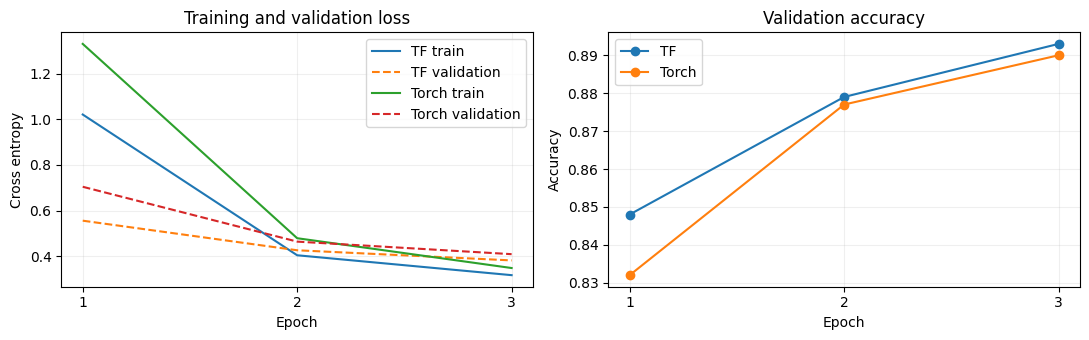

In [14]:
epochs = [1, 2, 3]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(epochs, history_tf.history['loss'], label='TF train')
axes[0].plot(epochs, history_tf.history['val_loss'], '--', label='TF validation')
axes[0].plot(epochs, torch_train_loss, label='Torch train')
axes[0].plot(epochs, torch_val_loss, '--', label='Torch validation')
axes[0].set(xlabel='Epoch', ylabel='Cross entropy', title='Training and validation loss')
axes[1].plot(epochs, history_tf.history['val_accuracy'], 'o-', label='TF')
axes[1].plot(epochs, torch_val_accuracy, 'o-', label='Torch')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Validation accuracy')
for ax in axes:
    ax.set_xticks(epochs); ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## ۱۱. ارزیابی روی test

تا اینجا test در آموزش مصرف نشده است. اکنون مدل‌های آموزش‌دیده را روی همان ۲۰۰۰ نمونهٔ آزمون ارزیابی می‌کنیم.
`evaluate` معیارها را محاسبه می‌کند؛ `predict` خروجی را تولید می‌کند.
در PyTorch محاسبهٔ معیار را خودمان با چند خط می‌نویسیم.

In [15]:
test_tf = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(batch_size)
test_result_tf = model_tf.evaluate(test_tf, verbose=0, return_dict=True)

model_pt.eval()
with torch.no_grad():
    test_logits_pt = model_pt(torch.from_numpy(x_test))
    test_loss_pt = loss_fn(test_logits_pt, torch.from_numpy(y_test)).item()
    test_accuracy_pt = (test_logits_pt.argmax(1).numpy() == y_test).mean()

print('TF test:', test_result_tf)
print('Torch test:', {'loss': test_loss_pt, 'accuracy': float(test_accuracy_pt)})

TF test: {'accuracy': 0.875, 'loss': 0.41804930567741394}
Torch test: {'loss': 0.44772616028785706, 'accuracy': 0.873}


## ۱۲. استفاده از مدل برای یک تصویر جدید

حتی برای یک تصویر، محور batch را نگه می‌داریم؛ شکل ورودی `(1,28,28)` است.
با Softmax، logitها را به احتمال تبدیل می‌کنیم. `argmax` کلاس دارای بیشترین احتمال را می‌دهد.
در کاربرد واقعی، تصویر جدید را هم مانند دادهٔ آموزشی نرمال کنید.

In [16]:
one_image = x_test[:1]
logits_tf = model_tf.predict(one_image, verbose=0)
probabilities_tf = tf.nn.softmax(logits_tf, axis=1).numpy()

with torch.no_grad():
    logits_pt = model_pt(torch.from_numpy(one_image))
    probabilities_pt = torch.softmax(logits_pt, dim=1).numpy()

print('True label:', y_test[0])
print('TF predicted label:', probabilities_tf.argmax(1)[0])
print('Torch predicted label:', probabilities_pt.argmax(1)[0])
print('Probability sums:', probabilities_tf.sum(), probabilities_pt.sum())

True label: 7
TF predicted label: 7
Torch predicted label: 7
Probability sums: 1.0 1.0


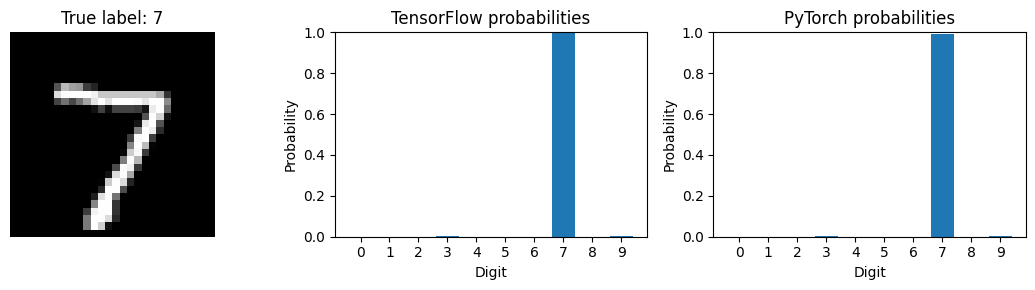

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].imshow(one_image[0], cmap='gray'); axes[0].axis('off')
axes[0].set_title(f'True label: {y_test[0]}')
axes[1].bar(range(10), probabilities_tf[0]); axes[1].set_title('TensorFlow probabilities')
axes[2].bar(range(10), probabilities_pt[0]); axes[2].set_title('PyTorch probabilities')
for ax in axes[1:]:
    ax.set(xlabel='Digit', ylabel='Probability', ylim=(0, 1)); ax.set_xticks(range(10))
plt.tight_layout(); plt.show()

## ۱۳. ذخیره و بارگذاری مدل برای پیش‌بینی

در Keras از فایل `.keras` استفاده می‌کنیم. در PyTorch، `state_dict` وزن‌ها را ذخیره می‌کند و
هنگام بارگذاری باید همان معماری را دوباره بسازیم.
این مثال برای استفادهٔ مدل در پیش‌بینی است؛ ادامهٔ کامل آموزش به وضعیت optimizer هم نیاز دارد که در درس ۰۷ توضیح داده شده است.

In [18]:
save_dir = root / 'artifacts' / '09_beginner_models'
save_dir.mkdir(parents=True, exist_ok=True)

model_tf.save(save_dir / 'model_tf.keras')
loaded_tf = keras.models.load_model(save_dir / 'model_tf.keras')

torch.save(model_pt.state_dict(), save_dir / 'model_pt.pt')
loaded_pt = nn.Sequential(nn.Flatten(), nn.Linear(784, 64), nn.ReLU(), nn.Linear(64, 10))
loaded_pt.load_state_dict(torch.load(save_dir / 'model_pt.pt', weights_only=True))
loaded_pt.eval()

np.testing.assert_allclose(loaded_tf(one_image).numpy(), logits_tf, atol=1e-6)
with torch.no_grad():
    np.testing.assert_allclose(loaded_pt(torch.from_numpy(one_image)).numpy(), logits_pt.numpy(), atol=1e-6)
print('Both saved models loaded correctly and produced the same outputs as before saving.')

Both saved models loaded correctly and produced the same outputs as before saving.


## ۱۴. دو روش دیگر تعریف مدل؛ آشنایی کوتاه

برای یک زنجیرهٔ ساده، Sequential کافی است. اگر بخواهیم جریان ورودی و خروجی را صریح بنویسیم،
در Keras از Functional API و در PyTorch از کلاس `nn.Module` و تابع `forward` استفاده می‌کنیم.
دو مدل زیر همان ساختار قبلی را دارند، ولی تازه ساخته شده‌اند و هنوز آموزش ندیده‌اند.

In [19]:
inputs = keras.Input(shape=(28, 28))
x = keras.layers.Flatten()(inputs)
x = keras.layers.Dense(64, activation='relu')(x)
outputs = keras.layers.Dense(10)(x)
functional_tf = keras.Model(inputs, outputs)
print('Functional TF output:', functional_tf(x_train[:2]).shape)

Functional TF output: (2, 10)


In [20]:
class DigitModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(784, 64)
        self.output = nn.Linear(64, 10)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = torch.relu(self.hidden(x))
        return self.output(x)

class_model_pt = DigitModel()
print('Class-based Torch output:', class_model_pt(torch.from_numpy(x_train[:2])).shape)

Class-based Torch output: torch.Size([2, 10])


## ۱۵. transform هنگام خواندن داده؛ مثال کوتاه

در پروژهٔ بزرگ‌تر می‌توان transform را هنگام تحویل هر نمونه انجام داد.
در TensorFlow، `map` تابع را روی نمونه‌ها اجرا می‌کند.
در PyTorch، Dataset سفارشی با `__len__` تعداد نمونه و با `__getitem__` نمونهٔ شمارهٔ خواسته‌شده را برمی‌گرداند.
برای فهم درس اصلی، همان TensorDataset قبلی کافی بود؛ این مثال فقط محل قرارگرفتن transform را نشان می‌دهد.

In [21]:
def normalize_tf(image, label):
    return tf.cast(image, tf.float32) / 255.0, label

raw_dataset_tf = tf.data.Dataset.from_tensor_slices((raw_x[:10], raw_y[:10]))
transformed_tf = raw_dataset_tf.map(normalize_tf).batch(2)
images_tf, labels_tf = next(iter(transformed_tf))
print('TF transformed batch:', images_tf.shape, images_tf.dtype)

TF transformed batch: (2, 28, 28) <dtype: 'float32'>


In [22]:
class DigitDataset(torch.utils.data.Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = torch.tensor(self.images[index]).float() / 255.0
        label = torch.tensor(int(self.labels[index]), dtype=torch.long)
        return image, label

transformed_pt = DataLoader(DigitDataset(raw_x[:10], raw_y[:10]), batch_size=2)
images_pt, labels_pt = next(iter(transformed_pt))
print('Torch transformed batch:', images_pt.shape, images_pt.dtype)
np.testing.assert_allclose(images_tf.numpy(), images_pt.numpy())

Torch transformed batch: torch.Size([2, 28, 28]) torch.float32


### خواندن داده‌های دیگر

در این درس فایل NPZ خواندیم. برای CSV معمولاً ابتدا `pandas.read_csv` و سپس تبدیل به NumPy کافی است.
برای پوشهٔ تصویر، ابزارهای آمادهٔ `keras.utils.image_dataset_from_directory` و `torchvision.datasets.ImageFolder` وجود دارند.
در torchvision معمولاً `ToTensor` تصویر uint8 را به تنسور با شکل `(C,H,W)` و مقیاس صفر تا یک تبدیل می‌کند؛
رفتار transform به نوع ورودی هم وابسته است. برای این درس نصب torchvision لازم نیست.
فقط خواندن فایل کافی نیست؛ شکل، نوع، مقیاس و برچسب‌ها باید مطابق ورودی مدل باشند.

## ۱۶. مقایسهٔ کارهای اصلی

| کار | TensorFlow / Keras | PyTorch |
|---|---|---|
| لایهٔ متصل | `Dense(64)` | `Linear(784,64)` |
| مدل زنجیره‌ای | `keras.Sequential` | `nn.Sequential` |
| تعریف صریح جریان مدل | Functional API | کلاس `nn.Module` و `forward` |
| دادهٔ batchشده | `tf.data.Dataset` | `Dataset` و `DataLoader` |
| transform نمونه | `Dataset.map` | در `__getitem__` یا transform آماده |
| شروع آموزش | `compile` و `fit` | حلقه و optimizer |
| گرادیان | داخل `fit` | `loss.backward()` |
| تغییر وزن | داخل `fit` | `optimizer.step()` |
| ارزیابی | `evaluate` | `eval` و `no_grad` و محاسبهٔ معیار |
| پیش‌بینی | `predict` یا فراخوانی مدل | فراخوانی مدل در حالت ارزیابی |
| ذخیرهٔ این مثال | `model.save` | `torch.save(model.state_dict())` |

در هر دو، ترتیب فکرکردن یکسان است: دادهٔ درست، شکل درست، مدل، loss، آموزش و ارزیابی.

## ۱۷. تمرین ساده

۱. تعداد واحدهای پنهان را از ۶۴ به ۳۲ تغییر دهید. در PyTorch ورودی لایهٔ خروجی را هم ۳۲ بگذارید.

۲. تعداد epoch را از ۳ به ۵ افزایش دهید و نمودار validation را ببینید.

۳. `x_test[5:6]` را به مدل بدهید و احتمال هر رقم را رسم کنید.

۴. توضیح دهید چرا خروجی دو مدل تازهٔ بخش ۱۴ با مدل‌های آموزش‌دیده متفاوت است.

۵. قبل از اجرای هر مدل، شکل ورودی و خروجی را روی کاغذ بنویسید.

## منابع رسمی


- [مدل Sequential در Keras](https://www.tensorflow.org/guide/keras/sequential_model)
- [شروع کار با PyTorch](https://docs.pytorch.org/tutorials/beginner/basics/intro.html)
- [Dataset و DataLoader](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)
- [تعریف مدل در PyTorch](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html)
- [tf.data و map](https://www.tensorflow.org/guide/data)
- [torchvision ToTensor](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.ToTensor.html)


بازبینی منابع و اجرای این درس: ۱۶ اکتبر ۲۰۲۶.